## What is Feature Engineering?
Feature Engineering is the process of creating, transforming, or selecting features to improve a Machine Learning model.

For example, suppose you're predicting house prices.

Original features:
- House size
- Number of bedrooms
- House age
You could create additional features:
- Price per square foot (if price is known, this is for analysis, not a prediction input).
- House age groups.
- Bedrooms per 1,000 square feet.
- Log-transformed house size.

## Feature transformations

### A. Log transformation
Useful when a numerical feature is highly right-skewed.

For example, income data often has a long right tail.

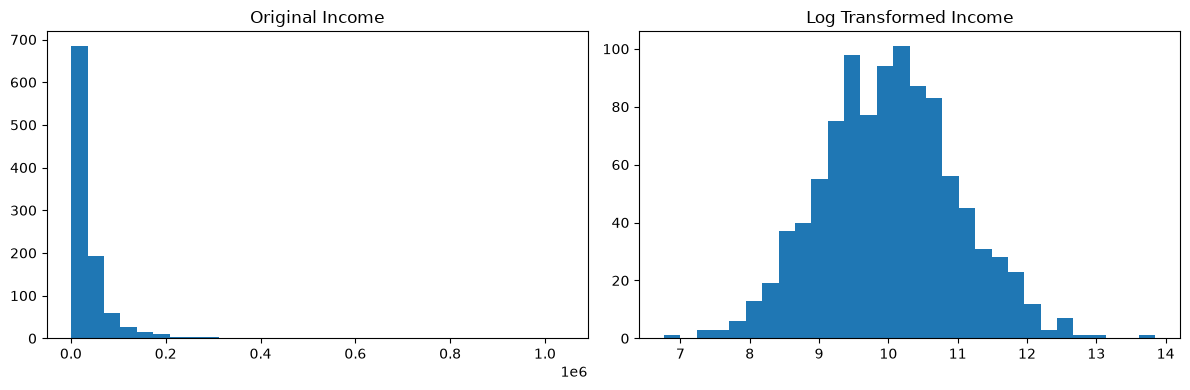

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

income = np.random.lognormal(
    mean=10,
    sigma=1,
    size=1000
)

df = pd.DataFrame({"Income": income})

df["Log_Income"] = np.log1p(df["Income"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["Income"], bins=30)
axes[0].set_title("Original Income")

axes[1].hist(df["Log_Income"], bins=30)
axes[1].set_title("Log Transformed Income")

plt.tight_layout()
plt.show()

np.log1p(x) calculates log(1 + x) and is useful when values include zero.

### B. Polynomial features

In [4]:
from sklearn.preprocessing import PolynomialFeatures

X = np.array([[2], [3], [4]])

poly = PolynomialFeatures(
    degree=2,
    include_bias=False
)

X_poly = poly.fit_transform(X)

print(X_poly)

[[ 2.  4.]
 [ 3.  9.]
 [ 4. 16.]]


### C. Interaction features

Sometimes two features together provide useful information.

For example:
\[
\text{Area}\times\text{Bedrooms}
\]

This creates an interaction feature.

In [7]:
from sklearn.preprocessing import PolynomialFeatures

X = pd.DataFrame({
    "Area": [1000, 1500, 2000, 2500],
    "Bedrooms": [2, 3, 3, 4]
})

interaction = PolynomialFeatures(
    degree=2,
    interaction_only=True,
    include_bias=False
)

X_interaction = interaction.fit_transform(X)

print(interaction.get_feature_names_out(X.columns))
print(X_interaction)

['Area' 'Bedrooms' 'Area Bedrooms']
[[1.0e+03 2.0e+00 2.0e+03]
 [1.5e+03 3.0e+00 4.5e+03]
 [2.0e+03 3.0e+00 6.0e+03]
 [2.5e+03 4.0e+00 1.0e+04]]


## 3. Handling outliers

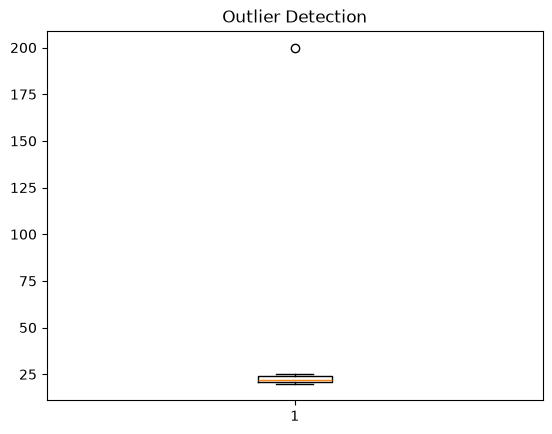

In [8]:
data = [20, 22, 21, 25, 24, 23, 22, 21, 200]

plt.boxplot(data)
plt.title("Outlier Detection")
plt.show()

The value 200 is much larger than the other observations.

Detect outliers using IQR

IQR stands for Interquartile Range.

IQR = Q3-Q1

Lower boundary:

Q1 - 1.5(IQR)

Upper boundary

Q3 + 1.5(IQR)

In [9]:
Q1 = np.percentile(data, 25)
Q3 = np.percentile(data, 75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = [
    x for x in data
    if x < lower or x > upper
]

print("Lower boundary:", lower)
print("Upper boundary:", upper)
print("Outliers:", outliers)

Lower boundary: 16.5
Upper boundary: 28.5
Outliers: [200]


Important: Outliers aren't always errors. A very expensive house might be a legitimate observation. Investigate before removing or changing it.

## 4. Feature selection

Not every feature helps a model.

For example, a house-price dataset might contain:
- House size
- Number of bedrooms
- House age
- Customer ID
- Random reference number
Customer ID may not contain meaningful predictive information.

Feature selection attempts to retain useful features and remove irrelevant or redundant ones.

#### Correlation-based inspection

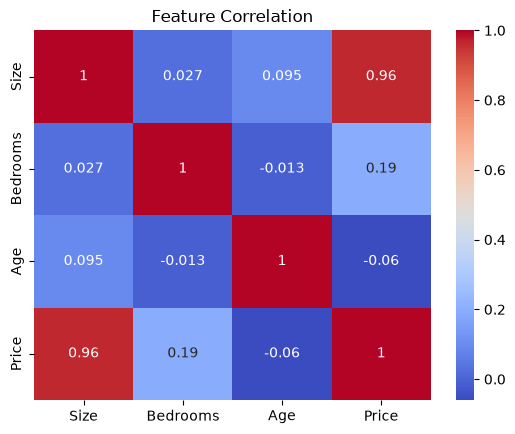

In [10]:
import seaborn as sns

np.random.seed(42)

df = pd.DataFrame({
    "Size": np.random.randint(500, 3000, 100),
    "Bedrooms": np.random.randint(1, 6, 100),
    "Age": np.random.randint(1, 40, 100),
})

df["Price"] = (
    df["Size"] * 0.05
    + df["Bedrooms"] * 5
    - df["Age"] * 0.5
    + np.random.normal(0, 5, 100)
)

correlation = df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Feature Correlation")
plt.show()

## 5. Practical feature engineering pipeline

In [11]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("polynomial", PolynomialFeatures(
        degree=2,
        include_bias=False
    )),
    ("scaler", StandardScaler()),
    ("regressor", Ridge(alpha=1.0))
])

This pipeline:
1. Fills missing numerical values.
2. Creates polynomial and interaction features.
3. Standardizes the transformed features.
4. Trains a Ridge Regression model.